In [59]:
import numpy as np
import pylab as plt
import jax
import jax.numpy as jnp

In [60]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [61]:
path_images = "/content/drive/MyDrive/dataset/DSA4212/celeba_1000.npz"
path_labels = "/content/drive/MyDrive/dataset/DSA4212/male_1000.npz"


In [62]:
images = np.load(path_images)["images"]
labels = np.load(path_labels)["male"]


In [63]:
images.shape

(1000, 96, 96)

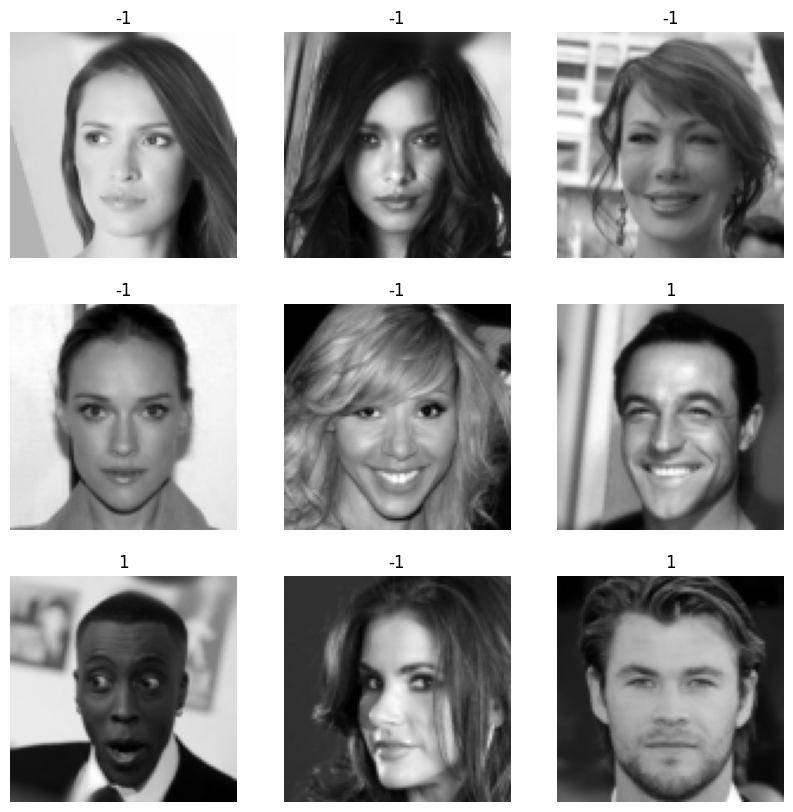

In [64]:
# prompt: let's plot a 3x3 grid of the 9 first images

fig = plt.figure(figsize=(10, 10))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(images[i], cmap="gray")
    plt.axis("off")
    title = "male" if labels[i] == 1 else "female"
    plt.title(labels[i])
plt.show()


(-0.5, 95.5, 95.5, -0.5)

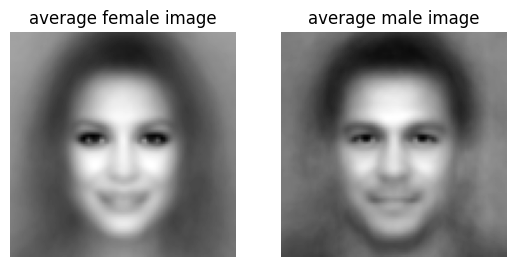

In [66]:
plt.subplot(1,2,1)
plt.title("average female image")
plt.imshow(np.mean(images[labels==-1], axis=0), cmap="gray")
plt.axis("off")

plt.subplot(1,2,2)
plt.title("average male image")
plt.imshow(np.mean(images[labels==1], axis=0), cmap="gray")
plt.axis("off")


In [67]:
images_flat = images.reshape(1000, -1)
images_flat.shape

(1000, 9216)

In [68]:
# implement the loss on a single image

# vmap it

# gradient of the loss

# logistis regresion: gradient descent

# make prediction

# error rate

# over-fitting?

In [69]:
def local_loss(beta,  # vector of parameters
               image, # single image represented as a long vector
               label, # {-1, +1}
               ):
  """ log(1 + exp(-y * dot(beta, image))) """
  return jnp.log(1. + jnp.exp(-label*jnp.dot(beta, image)))


In [70]:
_, dim = images_flat.shape

In [71]:
# intialize properly to avoid overflows
beta_init = np.random.normal(0, 1, size=dim) / np.sqrt(dim)

In [72]:
local_loss(beta_init, images_flat[0], labels[0])

Array(0.47480124, dtype=float32)

In [73]:
# jax.vmap( a functino to parallelize, in_axes=()
loss_all = jax.vmap(local_loss, in_axes=(None, 0, 0))

# why in_axes=(None, 0, 0) ?
# we will ve using loss(beta, images, labels)
#    None: we do not want to parallelize beta -- single parameter shared by all images
#    0: parallelize accross the first dimension of the matrix "images"
#    0: parallelize accross the first dimension of the vector "labels"



In [74]:
@jax.jit
def loss(beta, images_flat, labels):
  """ return the average of all the local losses """
  all_the_losses = loss_all(beta, images_flat, labels)
  return jnp.mean(all_the_losses)

# compute the gradient
loss_value_and_grad = jax.jit( jax.value_and_grad(loss) )

In [75]:
loss_value_and_grad(beta_init, images_flat, labels)

(Array(0.6472115, dtype=float32),
 Array([0.05512859, 0.05589778, 0.05605257, ..., 0.04957322, 0.04960644,
        0.04901849], dtype=float32))

In [76]:
# run gradient descent

beta = np.copy(beta_init)
lr = 0.005
niter = 1000
loss_history = []

for it in range(niter):
  # compute value and gradient
  v, g = loss_value_and_grad(beta, images_flat, labels)

  # do parameter update
  beta = beta - lr * g

  # save the loss
  loss_history.append(v)

  # printing
  if it % 50 == 0:
    print(f"iteration:{it} \t loss={v:2.4f}")


iteration:0 	 loss=0.6472
iteration:50 	 loss=0.5484
iteration:100 	 loss=0.4985
iteration:150 	 loss=0.4712
iteration:200 	 loss=0.4498
iteration:250 	 loss=0.4321
iteration:300 	 loss=0.4170
iteration:350 	 loss=0.4038
iteration:400 	 loss=0.3922
iteration:450 	 loss=0.3816
iteration:500 	 loss=0.3721
iteration:550 	 loss=0.3633
iteration:600 	 loss=0.3553
iteration:650 	 loss=0.3478
iteration:700 	 loss=0.3408
iteration:750 	 loss=0.3343
iteration:800 	 loss=0.3281
iteration:850 	 loss=0.3223
iteration:900 	 loss=0.3169
iteration:950 	 loss=0.3117


Text(0.5, 0, 'Iteration')

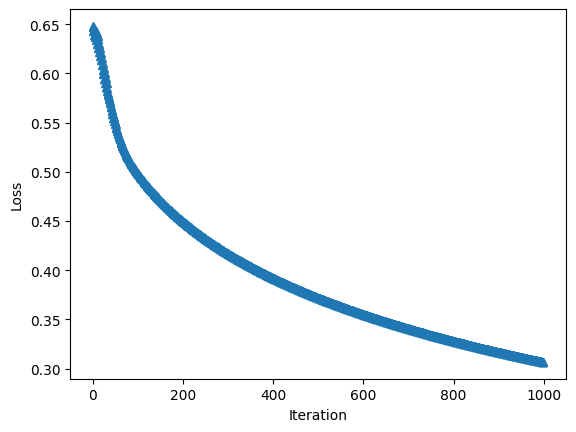

In [78]:
plt.plot(loss_history, "-^")
plt.ylabel("Loss")
plt.xlabel("Iteration")

In [79]:
def prediction_local(beta, image_flat):
  """ computes the probabilistic prediction of the model """
  proba = 1. / (1. + jnp.exp(-jnp.dot(beta, image_flat)))
  return proba

# parallelize
make_predictions = jax.vmap(prediction_local, in_axes=(None, 0))

In [80]:
# predict male when probabilistic prediction > 50%
predictions_male = ( make_predictions(beta, images_flat) > 0.5 )

In [82]:
male_true = (labels == 1)
accuracy = jnp.mean( predictions_male ==  male_true)
print(f"Accuracy of the model: {100*accuracy:2.2f}%")

Accuracy of the model: 89.90%
